# ⛽ Etanol x Gasolina (Região Sudeste)
**Análise dos preços da ANP · 1º semestre de 2025 vs. 1º semestre de 2026 · SP, MG, RJ e ES**

## Objetivo
Descobrir, em cada estado da região Sudeste do Brasil, **qual combustível compensa mais abastecer**: etanol ou gasolina ?

## A regra usada
Divide-se o **preço do etanol** pelo **preço da gasolina**. Como o etanol rende menos por litro, ele só compensa se for bem mais barato:

| Resultado da divisão | O que significa |
|---|---|
| **até 70%** | 🟢 **Etanol compensa** |
| **de 70% a 75%** | ⚪ **Depende do carro** (em carros flex mais modernos o etanol ainda pode valer a pena) |
| **acima de 75%** | 🟠 **Gasolina compensa** |

> Os dois períodos analisados usam a mesma gasolina, com 30% de etanol misturado (E30). A mistura só mudou para 32% (E32) em agosto de 2026, depois do período estudado. Por isso a comparação entre os anos é justa.

## Ferramentas
* **pandas**: ler, limpar, filtrar e organizar os dados em tabelas (DataFrames)
* **numpy**: fazer os cálculos
* **matplotlib**: criar os gráficos

## Roteiro
1. Ler os dados → 2. Entender os dados → 3. Limpar → 4. Ajustar os tipos → 5. Filtrar o Sudeste → 6. Analisar → 7. Concluir

**Fonte:** ANP, série histórica de levantamento de preços de combustíveis (arquivos semestrais "Automotivos" 2025/01 e 2026/01).

## 0. Instalação dos pacotes


In [ ]:
# Instala as três bibliotecas usadas no projeto
# %pip install pandas numpy matplotlib
#%pip install jinja2,

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: 'jinja2,': Expected semicolon (after name with no version specifier) or end
    jinja2,
          ^


## 1. Bibliotecas e configurações



In [2]:
import numpy as np                 # numpy: cálculos numéricos
import pandas as pd                # pandas: tabelas (DataFrames)
import matplotlib.pyplot as plt    # matplotlib: gráficos
import matplotlib.ticker as mtick  # formata os números dos eixos dos gráficos (ex.: "%", "R$")

# Caminho dos dois arquivos de dados (ficam na pasta "dados")
ARQUIVOS = {
    "2025": "dados/Preços_semestrais_-_AUTOMOTIVOS_2025_01.csv",
    "2026": "dados/Preços_semestrais_-_AUTOMOTIVOS_2026_01.csv",
}

# Limites da regra
LIMITE_ETANOL = 0.70    # até 70%: etanol compensa
LIMITE_GASOLINA = 0.75  # acima de 75%: gasolina compensa

# Nomes e cores das três faixas
FAIXAS = ["Etanol compensa", "Depende do carro", "Gasolina compensa"]
COR_FAIXA = {"Etanol compensa": "#1baf7a", "Depende do carro": "#d9d7cf", "Gasolina compensa": "#eb6834"}

# Outras cores dos gráficos
COR_ETANOL = "#1baf7a"   # verde para etanol
COR_GASOLINA = "#2a78d6" # azul para gasolina
COR_2025 = "#9a9893"     # cinza para 2025
COR_2026 = "#2a78d6"     # azul para 2026
TXT, TXT2 = "#0b0b0b", "#52514e"

# Mostra números com 2 casas decimais nas tabelas
pd.set_option("display.float_format", "{:,.2f}".format)

# Aparência padrão dos gráficos
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,   # tira bordas de cima e da direita
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TXT2,
    "xtick.color": TXT2, "ytick.color": TXT2,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlecolor": TXT,
    "axes.grid": True, "grid.color": "#e8e7e2", "font.size": 10,
})

def titulos(ax, titulo, subtitulo):
    """Coloca no gráfico um título curto em negrito e, logo abaixo, um subtítulo em cinza."""
    ax.set_title(subtitulo, loc="left", fontsize=10, color=TXT2, fontweight="normal", pad=10)
    ax.annotate(titulo, xy=(0, 1), xycoords="axes fraction", xytext=(0, 24), textcoords="offset points",
                fontsize=15, fontweight="bold", color=TXT, ha="left", va="bottom")

## 2. Leitura dos dados e criação do DataFrame
**Por quê?** Os dados vêm em dois arquivos CSV, um por ano. Lemos os dois, marcamos de qual ano é cada linha e juntamos tudo em **um único DataFrame** (uma tabela do pandas), para analisar os dois anos juntos.

Os arquivos da ANP usam `;` para separar as colunas e têm acentos, por isso informamos `sep=";"` e `encoding="utf-8-sig"`.

In [14]:
ARQUIVOS = {
    "2025": r"C:\Users\mathe\Documents\Python - Pandas\Projeto pratico\ca-2025-01\Preços semestrais - AUTOMOTIVOS_2025.01.csv",
    "2026": r"C:\Users\mathe\Documents\Python - Pandas\Projeto pratico\ca-2025-01\Preços semestrais - AUTOMOTIVOS_2026.01.csv",
}

In [15]:
from pathlib import Path

for arquivo in Path(r"C:\Users\mathe\Documents\Python - Pandas\Projeto pratico").rglob("*.csv"):
    print(arquivo)

C:\Users\mathe\Documents\Python - Pandas\Projeto pratico\ca-2025-01\Preços semestrais - AUTOMOTIVOS_2025.01.csv
C:\Users\mathe\Documents\Python - Pandas\Projeto pratico\ca-2025-01\Preços semestrais - AUTOMOTIVOS_2026.01.csv


In [16]:
tabelas = []                                   # lista vazia para guardar as tabelas
for ano, caminho in ARQUIVOS.items():          # repete para 2025 e para 2026
    tabela = pd.read_csv(caminho, sep=";", encoding="utf-8-sig", low_memory=False)  # lê o arquivo
    tabela["ano"] = ano                        # cria a coluna "ano"
    tabelas.append(tabela)                     # guarda na lista

df = pd.concat(tabelas, ignore_index=True)     # junta as duas tabelas em um só DataFrame

print(f"O DataFrame tem {df.shape[0]:,} linhas e {df.shape[1]} colunas")
df.head()                                      # mostra as 5 primeiras linhas

O DataFrame tem 851,941 linhas e 17 colunas


,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira,ano
0,NE,CE,SOBRAL,ECONOGÁS DO BRASIL DIST. DERIV. DE PET. BIOC. ...,08.775.979/0002-62,RUA TABELIÃO IDELFONSO CAVALCANTI,455,NaN,CENTRO,62010-000,GASOLINA,01/01/2025,"6,29",NaN,R$ / litro,RAIZEN,2025
1,NE,CE,SOBRAL,ECONOGÁS DO BRASIL DIST. DERIV. DE PET. BIOC. ...,08.775.979/0002-62,RUA TABELIÃO IDELFONSO CAVALCANTI,455,NaN,CENTRO,62010-000,GASOLINA ADITIVADA,01/01/2025,"6,49",NaN,R$ / litro,RAIZEN,2025
2,NE,CE,SOBRAL,ECONOGÁS DO BRASIL DIST. DERIV. DE PET. BIOC. ...,08.775.979/0002-62,RUA TABELIÃO IDELFONSO CAVALCANTI,455,NaN,CENTRO,62010-000,DIESEL S10,01/01/2025,"6,19",NaN,R$ / litro,RAIZEN,2025
3,NE,CE,SOBRAL,ECONOGÁS DO BRASIL DIST. DERIV. DE PET. BIOC. ...,08.775.979/0002-62,RUA TABELIÃO IDELFONSO CAVALCANTI,455,NaN,CENTRO,62010-000,ETANOL,01/01/2025,"5,19",NaN,R$ / litro,RAIZEN,2025
4,NE,CE,SOBRAL,V.C.EMPREENDIMENTOS LTDA,03.551.935/0002-35,AVENIDA JOSE EUCLIDES FERREIRA GOMES,30,POSTO FLASH,CORACAO DE JESUS,62043-070,GASOLINA,01/01/2025,"6,53",NaN,R$ / litro,RAIZEN,2025


## 3. Entendendo os dados
**Por quê?** Antes de limpar, precisamos saber **o que tem** na tabela: quais colunas existem, qual o tipo de cada uma e se há valores faltando.

In [17]:
# Para cada coluna: tipo do dado e quantos valores estão vazios
resumo = pd.DataFrame({
    "tipo": df.dtypes.astype(str),             # tipo de cada coluna
    "valores_vazios": df.isna().sum(),         # quantos valores vazios
})
resumo

,tipo,valores_vazios
Regiao - Sigla,str,9114
Estado - Sigla,str,9114
Municipio,str,9114
Revenda,str,9114
CNPJ da Revenda,str,9114
Nome da Rua,str,9114
Numero Rua,str,9178
Complemento,str,659167
Bairro,str,10704
Cep,str,9114


**O que encontramos:**
* Quase todas as colunas foram lidas como **texto**, inclusive o **preço** e a **data**. Com texto não dá para fazer contas nem trabalhar com datas, então será preciso **mudar a tipagem**.
* A coluna **"Valor de Compra"** está **totalmente vazia**, então não serve para a análise.
* Existem linhas em que **tudo** está vazio (no final do arquivo de 2025).
* Colunas como rua, número, bairro e CEP não são necessárias para a nossa pergunta.

## 4. Limpeza dos dados

### 4.1 Remover linhas vazias
**Por quê?** Linhas sem nenhuma informação só ocupam espaço e podem atrapalhar contagens.

In [18]:
linhas_antes = len(df)                                  # quantas linhas tinha antes
df = df.dropna(subset=["Produto"])                      # remove as linhas sem produto (as vazias)
print(f"Linhas vazias removidas: {linhas_antes - len(df):,}")

Linhas vazias removidas: 9,114


### 4.2 Manter só as colunas úteis e renomear
**Por quê?** Menos colunas deixam a tabela mais leve e fácil de ler. Nomes curtos e sem espaço deixam o código mais simples.

In [19]:
df = df[["ano", "Regiao - Sigla", "Estado - Sigla", "Municipio", "CNPJ da Revenda",
         "Produto", "Data da Coleta", "Valor de Venda", "Bandeira"]]   # escolhe as colunas

df = df.rename(columns={                                 # troca os nomes
    "Regiao - Sigla": "regiao",
    "Estado - Sigla": "uf",
    "Municipio": "municipio",
    "CNPJ da Revenda": "cnpj",
    "Produto": "produto",
    "Data da Coleta": "data",
    "Valor de Venda": "preco",
    "Bandeira": "bandeira",
})
df.head()

,ano,regiao,uf,municipio,cnpj,produto,data,preco,bandeira
0,2025,NE,CE,SOBRAL,08.775.979/0002-62,GASOLINA,01/01/2025,"6,29",RAIZEN
1,2025,NE,CE,SOBRAL,08.775.979/0002-62,GASOLINA ADITIVADA,01/01/2025,"6,49",RAIZEN
2,2025,NE,CE,SOBRAL,08.775.979/0002-62,DIESEL S10,01/01/2025,"6,19",RAIZEN
3,2025,NE,CE,SOBRAL,08.775.979/0002-62,ETANOL,01/01/2025,"5,19",RAIZEN
4,2025,NE,CE,SOBRAL,03.551.935/0002-35,GASOLINA,01/01/2025,"6,53",RAIZEN


## 5. Ajuste da tipagem
**Por quê?** Cada informação precisa estar no tipo certo:

| Coluna | Antes | Depois | Por quê |
|---|---|---|---|
| `preco` | texto ("6,29") | número decimal (6.29) | para calcular médias, divisões etc. O Python usa ponto como separador decimal, então trocamos a vírgula por ponto |
| `data` | texto ("01/01/2025") | data | para filtrar por mês e agrupar por semana |
| `regiao`, `uf`, `produto`, `bandeira`, `ano` | texto | categoria | são poucos valores que se repetem muito; como "categoria" ocupam bem menos memória |
| `cnpj` | texto com espaços | texto sem espaços | para identificar o posto corretamente |

In [20]:
memoria_antes = df.memory_usage(deep=True).sum() / 1024**2   # memória usada antes (em MB)

# Preço: troca a vírgula por ponto e converte para número decimal (float)
df["preco"] = df["preco"].str.replace(",", ".", regex=False).astype(float)

# Data: converte o texto dia/mês/ano para o tipo data
df["data"] = pd.to_datetime(df["data"], format="%d/%m/%Y")

# CNPJ: tira espaços sobrando no começo e no fim
df["cnpj"] = df["cnpj"].str.strip()

# Colunas com poucos valores diferentes viram "categoria"
for coluna in ["ano", "regiao", "uf", "produto", "bandeira"]:
    df[coluna] = df[coluna].astype("category")

memoria_depois = df.memory_usage(deep=True).sum() / 1024**2  # memória usada depois

print(f"Memória antes: {memoria_antes:,.0f} MB  →  depois: {memoria_depois:,.0f} MB")
print(df.dtypes)

Memória antes: 414 MB  →  depois: 125 MB
ano                category
regiao             category
uf                 category
municipio               str
cnpj                    str
produto            category
data         datetime64[us]
preco               float64
bandeira           category
dtype: object


### 5.1 Remover registros duplicados
**Por quê?** O mesmo posto não deveria ter dois preços para o mesmo produto no mesmo dia. Se tiver, é repetição e contaria em dobro.

In [21]:
duplicados = df.duplicated(subset=["cnpj", "produto", "data"]).sum()   # conta os repetidos
df = df.drop_duplicates(subset=["cnpj", "produto", "data"])            # remove os repetidos
print(f"Registros duplicados removidos: {duplicados}")

Registros duplicados removidos: 6


## 6. Filtro: região Sudeste, etanol e gasolina comum
**Por quê?** O estudo é só sobre o **Sudeste** e só compara **etanol** com **gasolina comum** (a gasolina aditivada, o diesel e o GNV ficam de fora porque não são a escolha de quem tem carro flex).

In [22]:
sudeste = df[
    (df["regiao"] == "SE") &                              # só a região Sudeste
    (df["produto"].isin(["ETANOL", "GASOLINA"]))          # só etanol e gasolina comum
].copy()

# Remove das categorias os valores que não existem mais depois do filtro (ex.: outros estados)
for coluna in ["regiao", "uf", "produto", "bandeira"]:
    sudeste[coluna] = sudeste[coluna].cat.remove_unused_categories()

print(f"Linhas no Sudeste: {len(sudeste):,}")
print(f"Estados: {list(sudeste['uf'].cat.categories)}")
print(f"Cidades pesquisadas: {sudeste['municipio'].nunique()}")
print(f"Postos pesquisados: {sudeste['cnpj'].nunique():,}")
print("\nRegistros por estado:")
print(sudeste["uf"].value_counts().to_string())

Linhas no Sudeste: 205,593
Estados: ['ES', 'MG', 'RJ', 'SP']
Cidades pesquisadas: 191
Postos pesquisados: 4,738

Registros por estado:
uf
SP    121838
MG     45018
RJ     31088
ES      7649


### 6.1 Conferindo se os preços fazem sentido
**Por quê?** Erros de digitação (ex.: R$ 0,60 ou R$ 60,00) distorceriam os resultados. Olhamos o menor, o maior e os percentis com o **numpy**.

In [23]:
for produto in ["ETANOL", "GASOLINA"]:
    precos = sudeste.loc[sudeste["produto"] == produto, "preco"].to_numpy()   # transforma em array do numpy
    p1, p50, p99 = np.percentile(precos, [1, 50, 99])                         # percentis 1%, 50% e 99%
    print(f"{produto:9s} mínimo R$ {np.min(precos):.2f} | 1%: R$ {p1:.2f} | mediana R$ {p50:.2f} "
          f"| 99%: R$ {p99:.2f} | máximo R$ {np.max(precos):.2f}")

ETANOL    mínimo R$ 2.89 | 1%: R$ 3.44 | mediana R$ 4.37 | 99%: R$ 5.58 | máximo R$ 6.59
GASOLINA  mínimo R$ 4.99 | 1%: R$ 5.49 | mediana R$ 6.29 | 99%: R$ 7.39 | máximo R$ 9.79


Os valores mínimo e máximo são plausíveis para combustível (nenhum preço absurdo), então **não é preciso remover nenhum valor**.

> **Por que usar a mediana e não a média?** A mediana é o valor do meio: metade dos postos cobra menos e metade cobra mais. Ela não é "puxada" por alguns postos muito caros ou muito baratos, então representa melhor o preço típico.

## 7. Análise

### 7.1 Preço típico em cada estado e quanto subiu
**Por quê?** Primeiro vemos o preço mediano de cada combustível por estado e quanto ele mudou de 2025 para 2026.

In [24]:
# Tabela: preço mediano por estado, combustível e ano
precos = sudeste.pivot_table(index="uf", columns=["produto", "ano"], values="preco",
                             aggfunc="median", observed=True)

# Variação % calculada com numpy: (2026 ÷ 2025 − 1) × 100
for produto in ["ETANOL", "GASOLINA"]:
    precos[(produto, "variação %")] = np.round(
        (precos[(produto, "2026")].to_numpy() / precos[(produto, "2025")].to_numpy() - 1) * 100, 1)

precos = precos[["ETANOL", "GASOLINA"]]   # organiza a ordem das colunas
precos

produto ETANOL                 GASOLINA                
ano       2025 2026 variação %     2025 2026 variação %
uf                                                     
ES        4.54 4.89       7.70     6.29 6.49       3.20
MG        4.38 4.59       4.80     6.19 6.34       2.40
RJ        4.59 4.99       8.70     6.19 6.55       5.80
SP        4.09 4.29       4.90     6.09 6.39       4.90

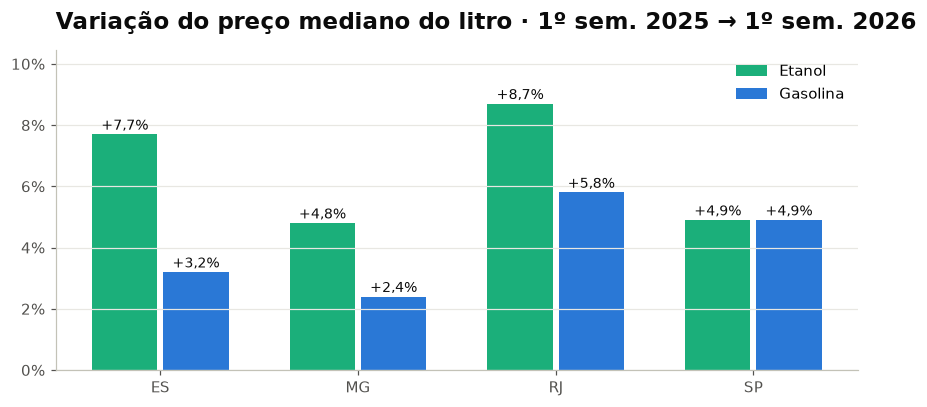

In [30]:
fig, ax = plt.subplots(figsize=(8, 3.8))
estados = precos.index.tolist()
x = np.arange(len(estados))                     # posição de cada estado no eixo
largura = 0.36

# Barras de variação do etanol e da gasolina, lado a lado
ax.bar(x - largura / 2, precos[("ETANOL", "variação %")], largura - 0.03, color=COR_ETANOL, label="Etanol")
ax.bar(x + largura / 2, precos[("GASOLINA", "variação %")], largura - 0.03, color=COR_GASOLINA, label="Gasolina")

# Escreve o valor em cima de cada barra
for i in range(len(estados)):
    for desloc, prod in [(-largura / 2, "ETANOL"), (largura / 2, "GASOLINA")]:
        v = precos[(prod, "variação %")].iloc[i]
        ax.text(x[i] + desloc, v + 0.15, f"+{v:.1f}%".replace(".", ","), ha="center", fontsize=9, color=TXT)

ax.set_xticks(x, estados)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, precos.xs("variação %", axis=1, level=1).to_numpy().max() * 1.2)

# Título do gráfico
ax.set_title("Variação do preço mediano do litro · 1º sem. 2025 → 1º sem. 2026",
             loc="left", fontsize=15, fontweight="bold", pad=14)

ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("variacao_precos_sudeste.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

### 7.2 O que compensa em cada estado: a razão etanol ÷ gasolina
**Por quê?** Saber só o preço não basta: precisamos **comparar** os dois combustíveis. Calculamos a razão e classificamos em uma das três faixas.

Além da média de cada semestre, olhamos também **junho**, o mês mais recente dos dados, para ver como o semestre terminou.

In [36]:
## Coluna auxiliar: número do mês de cada coleta (1 a 12)
sudeste["mes"] = sudeste["data"].dt.month

def razao_por_estado(dados):
    """Calcula preço mediano do etanol ÷ preço mediano da gasolina, por estado e ano."""
    tabela = dados.pivot_table(index="uf", columns=["ano", "produto"], values="preco",
                               aggfunc="median", observed=True)
    return pd.DataFrame({
        ano: tabela[(ano, "ETANOL")].to_numpy() / tabela[(ano, "GASOLINA")].to_numpy()
        for ano in ["2025", "2026"]
    }, index=tabela.index)

semestre = razao_por_estado(sudeste)                       # semestre inteiro
junho = razao_por_estado(sudeste[sudeste["mes"] == 6])     # só junho

razao = pd.DataFrame({
    "1º sem. 2025": semestre["2025"],
    "1º sem. 2026": semestre["2026"],
    "Junho 2025": junho["2025"],
    "Junho 2026": junho["2026"],
})

def classificar(valores):
    """Recebe as razões e devolve a faixa de cada uma, usando np.where do numpy."""
    valores = np.asarray(valores, dtype=float)
    return np.where(valores <= LIMITE_ETANOL, "Etanol compensa",          # até 70%
           np.where(valores <= LIMITE_GASOLINA, "Depende do carro",       # de 70% a 75%
                    "Gasolina compensa"))                                  # acima de 75%

faixas = razao.apply(classificar)    # aplica a classificação em todas as colunas

# Mostra a razão em porcentagem (ex.: 67.1 = 67,1%)
(razao * 100).round(1)

,1º sem. 2025,1º sem. 2026,Junho 2025,Junho 2026
uf,,,,
ES,72.20,75.30,75.00,72.60
MG,70.80,72.40,70.40,65.60
RJ,74.20,76.20,74.10,73.10
SP,67.20,67.10,66.60,59.60


In [37]:
# Mostra o que compensa em cada estado e período
faixas

,1º sem. 2025,1º sem. 2026,Junho 2025,Junho 2026
uf,,,,
ES,Depende do carro,Gasolina compensa,Depende do carro,Depende do carro
MG,Depende do carro,Depende do carro,Depende do carro,Etanol compensa
RJ,Depende do carro,Gasolina compensa,Depende do carro,Depende do carro
SP,Etanol compensa,Etanol compensa,Etanol compensa,Etanol compensa


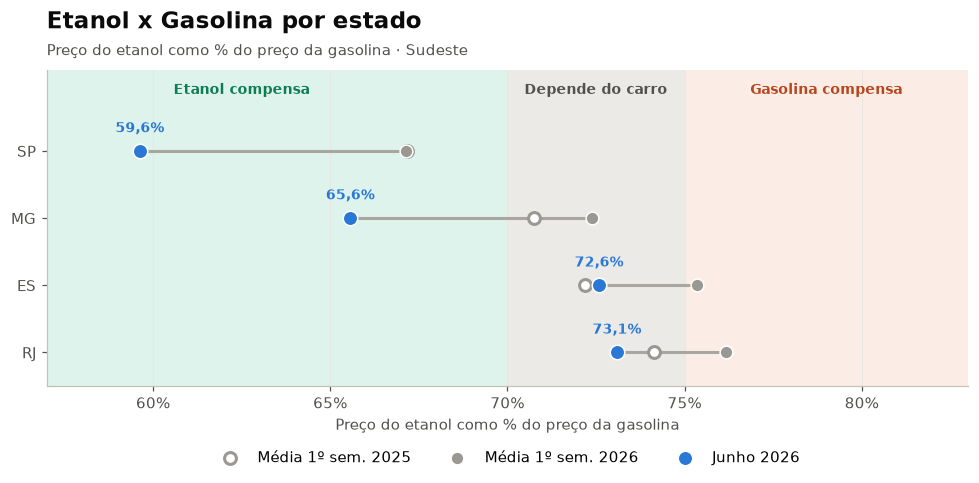

In [38]:
fig, ax = plt.subplots(figsize=(9, 4.6))

# Pinta o fundo com as três faixas
ax.axvspan(0.55, LIMITE_ETANOL, color=COR_FAIXA["Etanol compensa"], alpha=0.15, linewidth=0)
ax.axvspan(LIMITE_ETANOL, LIMITE_GASOLINA, color=COR_FAIXA["Depende do carro"], alpha=0.5, linewidth=0)
ax.axvspan(LIMITE_GASOLINA, 0.85, color=COR_FAIXA["Gasolina compensa"], alpha=0.12, linewidth=0)
ax.text(0.625, -0.85, "Etanol compensa", ha="center", color="#0e7c55", fontsize=9, fontweight="bold")
ax.text(0.725, -0.85, "Depende do carro", ha="center", color=TXT2, fontsize=9, fontweight="bold")
ax.text(0.79, -0.85, "Gasolina compensa", ha="center", color="#b8461c", fontsize=9, fontweight="bold")

ordem = razao.sort_values("Junho 2026").index      # ordena os estados do mais vantajoso ao menos
y = np.arange(len(ordem))
r = razao.loc[ordem]

# Linha ligando o semestre 2026 a junho 2026 (mostra o movimento)
ax.hlines(y, r["1º sem. 2026"], r["Junho 2026"], color="#a8a69f", linewidth=2)
# Um ponto para cada período
ax.scatter(r["1º sem. 2025"], y, s=60, color="white", edgecolor=COR_2025, linewidth=2, zorder=3, label="Média 1º sem. 2025")
ax.scatter(r["1º sem. 2026"], y, s=70, color=COR_2025, edgecolor="white", zorder=3, label="Média 1º sem. 2026")
ax.scatter(r["Junho 2026"], y, s=90, color=COR_2026, edgecolor="white", zorder=4, label="Junho 2026")
# Escreve o valor de junho/2026 ao lado do ponto azul
for yi, v in zip(y, r["Junho 2026"]):
    ax.text(v, yi - 0.28, f"{v:.1%}".replace(".", ","), ha="center", fontsize=9, color=COR_2026, fontweight="bold")

ax.set_yticks(y, ordem)
ax.set_ylim(len(ordem) - 0.5, -1.2)
ax.set_xlim(0.57, 0.83)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Preço do etanol como % do preço da gasolina")
titulos(ax, "Etanol x Gasolina por estado", "Preço do etanol como % do preço da gasolina · Sudeste")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("razao_sudeste.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

#### Como interpretar este gráfico:
* **Eixo horizontal:** quanto o etanol custa em relação à gasolina. Ex.: 60% = o litro de etanol custa 60% do litro de gasolina. **Quanto mais à esquerda, mais barato o etanol.**
* **Cores de fundo:** 🟢 verde = etanol compensa (até 70%) · ⚪ cinza = depende do carro (70% a 75%) · 🟠 laranja = gasolina compensa (acima de 75%). O que importa é **em qual cor o ponto cai**.
* **Pontos de cada estado:** bolinha vazada = média do 1º semestre de 2025 · bolinha cinza = média do 1º semestre de 2026 · **bolinha azul com o número = junho de 2026** (o dado mais recente). A linha cinza mostra para onde o estado andou no fim do semestre.


* **SP:** sempre no verde e chegou a 59,6% em junho. O etanol compensa com folga.
* **MG:** a média ficou no cinza, mas em junho foi para 65,6% (verde). O etanol passou a compensar no fim do semestre.
* **ES e RJ:** a média de 2026 ficou no laranja (gasolina compensa) e em junho voltaram para o cinza (72,6% e 73,1%): melhorou para o etanol, mas ainda depende do carro.

**Em uma frase:** todos os estados andaram para a esquerda em junho (o etanol ficou mais vantajoso), mas só SP e MG chegaram à faixa em que ele compensa para qualquer carro.

### 7.3 Semana a semana em cada estado
**Por quê?** A média do semestre pode esconder mudanças. Acompanhando semana a semana dá para ver **quando** o etanol ficou mais ou menos vantajoso.

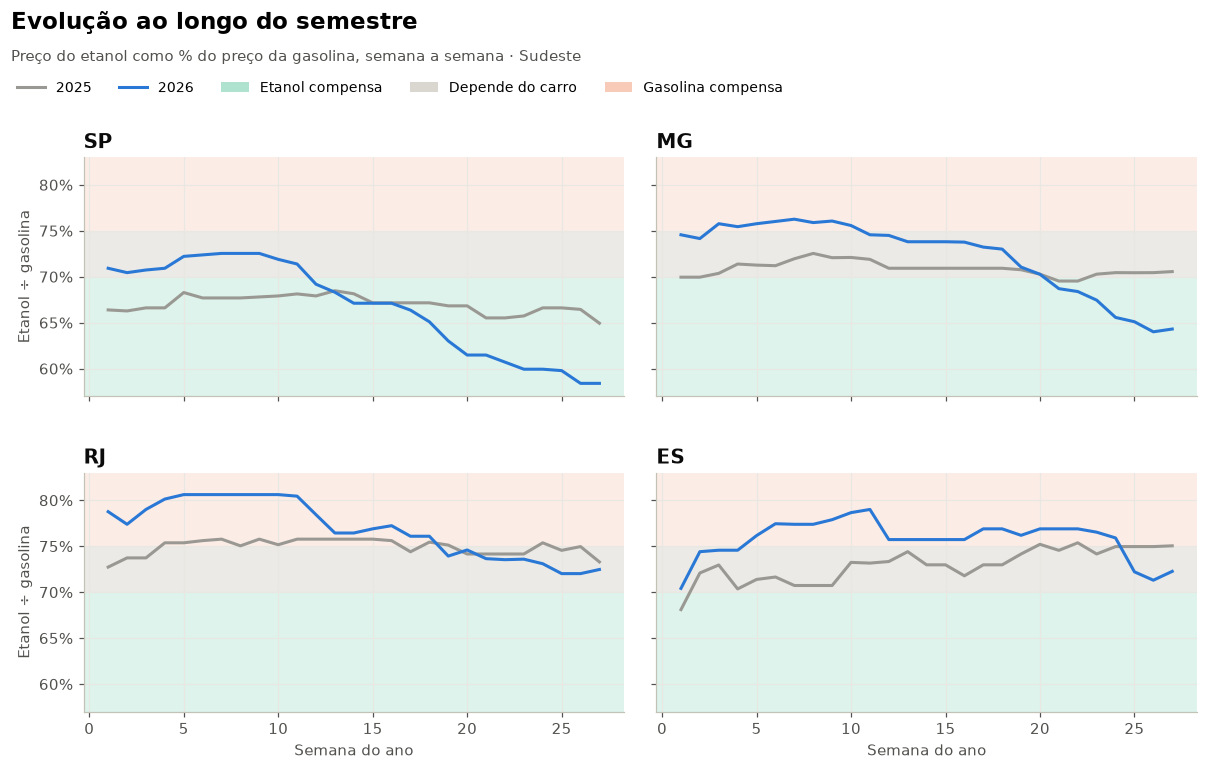

In [39]:
# Preço mediano por estado, ano, produto e semana
semanal = (sudeste
           .groupby(["uf", "ano", "produto", pd.Grouper(key="data", freq="W")], observed=True)["preco"]
           .median()
           .unstack("produto")       # etanol e gasolina lado a lado
           .reset_index())
semanal["razao"] = semanal["ETANOL"].to_numpy() / semanal["GASOLINA"].to_numpy()   # razão com numpy
semanal["semana"] = semanal["data"].dt.isocalendar().week.astype(int)               # número da semana

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)   # 4 gráficos (2x2)
for ax, estado in zip(axes.flat, ["SP", "MG", "RJ", "ES"]):
    # Fundo com as três faixas
    ax.axhspan(0.55, LIMITE_ETANOL, color=COR_FAIXA["Etanol compensa"], alpha=0.15, linewidth=0)
    ax.axhspan(LIMITE_ETANOL, LIMITE_GASOLINA, color=COR_FAIXA["Depende do carro"], alpha=0.5, linewidth=0)
    ax.axhspan(LIMITE_GASOLINA, 0.85, color=COR_FAIXA["Gasolina compensa"], alpha=0.12, linewidth=0)
    # Uma linha para cada ano
    for ano, cor in [("2025", COR_2025), ("2026", COR_2026)]:
        d = semanal[(semanal["uf"] == estado) & (semanal["ano"] == ano)]
        ax.plot(d["semana"], d["razao"], color=cor, linewidth=2, label=f"1º sem. {ano}")
    ax.set_title(estado, loc="left")
    ax.set_ylim(0.57, 0.83)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))

axes[1, 0].set_xlabel("Semana do ano")
axes[1, 1].set_xlabel("Semana do ano")
axes[0, 0].set_ylabel("Etanol ÷ gasolina")
axes[1, 0].set_ylabel("Etanol ÷ gasolina")
# Título e subtítulo curtos
fig.suptitle("Evolução ao longo do semestre", fontsize=15, fontweight="bold", x=0.01, ha="left", y=0.99)
fig.text(0.01, 0.925, "Preço do etanol como % do preço da gasolina, semana a semana · Sudeste",
         fontsize=10, color=TXT2, ha="left")

# Uma única legenda no topo: as duas linhas (anos) e as três faixas (cores de fundo)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
itens = [Line2D([0], [0], color=COR_2025, linewidth=2, label="2025"),
         Line2D([0], [0], color=COR_2026, linewidth=2, label="2026"),
         Patch(facecolor=COR_FAIXA["Etanol compensa"], alpha=0.35, label="Etanol compensa"),
         Patch(facecolor=COR_FAIXA["Depende do carro"], label="Depende do carro"),
         Patch(facecolor=COR_FAIXA["Gasolina compensa"], alpha=0.35, label="Gasolina compensa")]
fig.legend(handles=itens, loc="upper left", bbox_to_anchor=(0.005, 0.915), ncol=5, frameon=False, fontsize=9)

# Posiciona os 4 gráficos deixando espaço no topo para título, subtítulo e legenda
plt.subplots_adjust(top=0.80, bottom=0.08, left=0.07, right=0.99, hspace=0.32, wspace=0.06)
plt.savefig("semanal_sudeste.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

#### Como interpretar  este gráfico:
* **Um quadro para cada estado.** O eixo horizontal são as semanas do ano (semana 1 = começo de janeiro, semana 26 = fim de junho).
* **Eixo vertical:** quanto o etanol custa em relação à gasolina. **Quanto mais para baixo, mais barato o etanol.**
* **Cores de fundo:** 🟢 verde = etanol compensa (até 70%) · ⚪ cinza = depende do carro (70% a 75%) · 🟠 laranja = gasolina compensa (acima de 75%).
* **Linhas:** cinza = 1º semestre de 2025 · azul = 1º semestre de 2026.


* **SP:** em 2025 ficou no verde o semestre todo. Em 2026 começou no cinza, entrou no verde no fim de março (semana 12) e terminou junho perto de 58%, o etanol mais vantajoso de todo o período.
* **MG:** em 2025 ficou "em cima do muro", perto dos 70%. Em 2026 passou fevereiro e o começo de março no laranja (até ~76%), cruzou para o verde no fim de maio (semana 21) e terminou em ~64%.
* **RJ:** em 2026 ficou no laranja de janeiro até o começo de maio (até ~81%), depois desceu para o cinza e terminou em ~72%. Não chegou ao verde.
* **ES:** em 2026 ficou no laranja quase o semestre todo e só caiu para o cinza nas últimas semanas de junho (~72%).

**Em uma frase:** em 2026 o etanol começou o ano mais caro que em 2025 em todos os estados, mas a partir de maio a linha azul despencou. Em SP e MG ela entrou no verde; em RJ e ES, só chegou ao cinza.

### 7.4 Na prática: quanto custa rodar 100 km com os carros mais vendidos?
**Por quê?** A razão em % é útil, mas em **reais** e com **carros que as pessoas realmente compram** fica muito mais fácil de entender.

Escolhi os **5 carros de passeio mais vendidos de 2026** (emplacamentos de janeiro a setembro, Fenabrave), na versão de entrada com motor **1.0 aspirado e câmbio manual**, e usei o consumo **na cidade** (uso do dia a dia) medido pelo **Inmetro** (tabela PBE Veicular 2026):

| Posição em vendas | Carro | Etanol cidade (km/l) | Gasolina cidade (km/l) |
|---|---|---|---|
| 1º | VW Polo 1.0 MPI | 9,3 | 13,5 |
| 2º | Fiat Argo 1.0 | 9,4 | 13,6 |
| 3º | Chevrolet Onix 1.0 | 9,5 | 13,5 |
| 4º | Hyundai HB20 1.0 | 9,9 | 13,3 |
| 5º | Fiat Mobi 1.0 Like | 10,1 | 14,5 |

*O consumo real varia com a conservação do carro, o trânsito e o jeito de dirigir.*

**Cálculo:** custo para rodar 100 km = (100 ÷ km por litro) × preço do litro. Usamos os preços medianos de **junho de 2026**, os mais recentes.

In [41]:
# Tabela com o consumo de cada carro na cidade (km por litro), segundo o Inmetro
carros = pd.DataFrame({
    "carro": ["Polo 1.0", "Argo 1.0", "Onix 1.0", "HB20 1.0", "Mobi 1.0"],
    "km_l_etanol": [9.3, 9.4, 9.5, 9.9, 10.1],
    "km_l_gasolina": [13.5, 13.6, 13.5, 13.3, 14.5],
}).set_index("carro")

# Ponto de equilíbrio de cada carro: até quanto % do preço da gasolina o etanol ainda compensa
# (é o rendimento do etanol dividido pelo rendimento da gasolina)
carros["etanol compensa até"] = carros["km_l_etanol"].to_numpy() / carros["km_l_gasolina"].to_numpy()

# Mostra a tabela, com o ponto de equilíbrio em % (ex.: 68.9 = 68,9%)
carros.assign(**{"etanol compensa até (%)": (carros["etanol compensa até"] * 100).round(1)}).drop(columns="etanol compensa até")


,km_l_etanol,km_l_gasolina,etanol compensa até (%)
carro,,,
Polo 1.0,9.30,13.50,68.90
Argo 1.0,9.40,13.60,69.10
Onix 1.0,9.50,13.50,70.40
HB20 1.0,9.90,13.30,74.40
Mobi 1.0,10.10,14.50,69.70


Repare que **cada carro tem o seu próprio limite**: em quatro deles o etanol compensa até perto de 69–70% do preço da gasolina, mas no **HB20** vai até cerca de **74%**, porque ele perde menos rendimento com etanol.
É exatamente por isso que a regra tem a faixa **"depende do carro"** entre 70% e 75%.

In [43]:
# Preço mediano de junho/2026 por estado
junho_2026 = sudeste[(sudeste["ano"] == "2026") & (sudeste["mes"] == 6)]
preco_junho = junho_2026.pivot_table(index="uf", columns="produto", values="preco",
                                     aggfunc="median", observed=True)

linhas = []                                          # lista para guardar cada combinação estado + carro
for uf in preco_junho.index:                         # para cada estado...
    for carro in carros.index:                       # ...e para cada carro
        preco_e = preco_junho.loc[uf, "ETANOL"]      # preço do etanol no estado
        preco_g = preco_junho.loc[uf, "GASOLINA"]    # preço da gasolina no estado
        custo_e = 100 / carros.loc[carro, "km_l_etanol"] * preco_e     # custo de 100 km com etanol
        custo_g = 100 / carros.loc[carro, "km_l_gasolina"] * preco_g   # custo de 100 km com gasolina
        linhas.append({"estado": uf, "carro": carro,
                       "custo 100 km etanol": custo_e, "custo 100 km gasolina": custo_g})

custo = pd.DataFrame(linhas)                          # transforma a lista em DataFrame
custo["economia com etanol (R$)"] = np.round(          # positivo = etanol mais barato
    custo["custo 100 km gasolina"].to_numpy() - custo["custo 100 km etanol"].to_numpy(), 2)
custo["mais barato"] = np.where(custo["economia com etanol (R$)"] > 0, "Etanol", "Gasolina")

# Mostra a tabela com os valores em reais arredondados para 2 casas
custo.round(2)

,estado,carro,custo 100 km etanol,custo 100 km gasolina,economia com etanol (R$),mais barato
0,ES,Polo 1.0,51.83,49.19,-2.64,Gasolina
1,ES,Argo 1.0,51.28,48.82,-2.45,Gasolina
2,ES,Onix 1.0,50.74,49.19,-1.55,Gasolina
3,ES,HB20 1.0,48.69,49.92,1.24,Etanol
4,ES,Mobi 1.0,47.72,45.79,-1.93,Gasolina
5,MG,Polo 1.0,45.05,47.33,2.28,Etanol
6,MG,Argo 1.0,44.57,46.99,2.41,Etanol
7,MG,Onix 1.0,44.11,47.33,3.23,Etanol
8,MG,HB20 1.0,42.32,48.05,5.72,Etanol
9,MG,Mobi 1.0,41.49,44.07,2.58,Etanol


In [44]:
# Resumo em uma tabela: estados nas linhas, carros nas colunas, qual combustível sai mais barato
custo.pivot(index="estado", columns="carro", values="mais barato").loc[["SP", "MG", "ES", "RJ"]]

carro,Argo 1.0,HB20 1.0,Mobi 1.0,Onix 1.0,Polo 1.0
estado,,,,,
SP,Etanol,Etanol,Etanol,Etanol,Etanol
MG,Etanol,Etanol,Etanol,Etanol,Etanol
ES,Gasolina,Etanol,Gasolina,Gasolina,Gasolina
RJ,Gasolina,Etanol,Gasolina,Gasolina,Gasolina


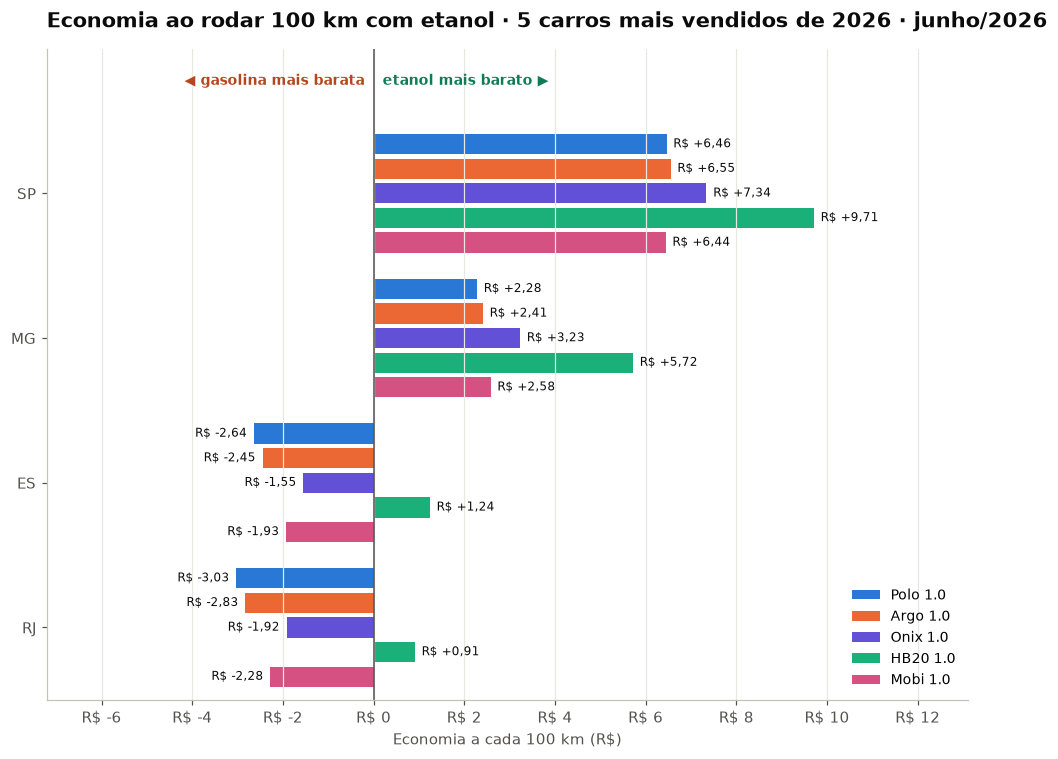

In [47]:
# Gráfico: economia com etanol para rodar 100 km, por estado e por carro
tabela = custo.pivot(index="estado", columns="carro", values="economia com etanol (R$)").loc[["SP", "MG", "ES", "RJ"]]
cores_carro = {"Polo 1.0": "#2a78d6", "Argo 1.0": "#eb6834", "Onix 1.0": "#6250d6", "HB20 1.0": "#1baf7a", "Mobi 1.0": "#d55181"}

fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(tabela))                 # posição de cada estado
altura = 0.17                              # espessura de cada barra
for i, carro in enumerate(carros.index):
    valores = tabela[carro].to_numpy()
    pos = y + (i - 2) * altura             # desloca cada carro um pouquinho
    ax.barh(pos, valores, altura - 0.03, color=cores_carro[carro], label=carro)
    for p, v in zip(pos, valores):         # escreve o valor ao lado da barra
        ax.text(v + (0.15 if v >= 0 else -0.15), p, f"R$ {v:+.2f}".replace(".", ","),
                va="center", ha="left" if v >= 0 else "right", fontsize=8, color=TXT)

ax.axvline(0, color=TXT2, linewidth=1)     # linha do zero
ax.set_yticks(y, tabela.index)
ax.invert_yaxis()
limite = np.abs(tabela.to_numpy()).max() * 1.35
ax.set_xlim(-limite * 0.55, limite)
ax.xaxis.set_major_locator(mtick.MultipleLocator(2))   # marcações de 2 em 2 reais
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"R$ {v:.0f}"))
ax.text(0.2, -0.75, "etanol mais barato ▶", color="#0e7c55", fontsize=9, fontweight="bold")
ax.text(-0.2, -0.75, "◀ gasolina mais barata", color="#b8461c", fontsize=9, fontweight="bold", ha="right")
ax.set_ylim(len(tabela) - 0.5, -1.0)
ax.set_xlabel("Economia a cada 100 km (R$)")
# Título do gráfico
ax.set_title("Economia ao rodar 100 km com etanol · 5 carros mais vendidos de 2026 · junho/2026",
             loc="left", fontsize=14, fontweight="bold", pad=14)
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("custo_100km_sudeste.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

### 7.5 Cidades onde o etanol mais compensa (junho/2026)
**Por quê?** Dentro do mesmo estado os preços variam bastante. Listamos as cidades com a menor razão em junho/2026, considerando apenas cidades com **pelo menos 5 postos** pesquisados (com poucos postos o resultado seria pouco confiável).

In [48]:
cidades = junho_2026.pivot_table(index=["uf", "municipio"], columns="produto", values="preco",
                                 aggfunc="median", observed=True)
postos = junho_2026.groupby(["uf", "municipio"], observed=True)["cnpj"].nunique()   # nº de postos por cidade

cidades["postos"] = postos
cidades["razao"] = cidades["ETANOL"].to_numpy() / cidades["GASOLINA"].to_numpy()
cidades["faixa"] = classificar(cidades["razao"].to_numpy())
cidades = cidades[cidades["postos"] >= 5].sort_values("razao")   # só cidades com 5+ postos

print(f"Cidades analisadas: {len(cidades)}")

# Conta quantas cidades de cada estado ficaram em cada faixa
pd.crosstab(cidades.index.get_level_values("uf"), cidades["faixa"],
            rownames=["estado"], colnames=["faixa"], margins=True, margins_name="Total")[FAIXAS + ["Total"]]

Cidades analisadas: 184


faixa,Etanol compensa,Depende do carro,Gasolina compensa,Total
estado,,,,
ES,1,6,1,8
MG,45,8,0,53
RJ,2,21,4,27
SP,96,0,0,96
Total,144,35,5,184


In [50]:
# 10 cidades onde o etanol mais compensa (menor razão); razão em % (ex.: 50.3 = 50,3%)
cidades.assign(razao=(cidades["razao"] * 100).round(1)).head(10)

produto                   ETANOL  GASOLINA  postos  razao            faixa
uf municipio                                                              
SP SAO JOSE DO RIO PRETO    3.19      6.34      31  50.30  Etanol compensa
   ADAMANTINA               3.29      6.43       8  51.20  Etanol compensa
   LINS                     3.19      6.19      13  51.50  Etanol compensa
   PRESIDENTE PRUDENTE      3.39      6.55      18  51.80  Etanol compensa
   BIRIGUI                  3.44      6.59      12  52.20  Etanol compensa
   VOTUPORANGA              3.49      6.59      10  53.00  Etanol compensa
   PARAGUACU PAULISTA       3.29      6.19       5  53.20  Etanol compensa
   OLIMPIA                  3.35      6.27       8  53.40  Etanol compensa
   VOTORANTIM               3.49      6.49       9  53.80  Etanol compensa
   ARACATUBA                3.39      6.29      21  53.90  Etanol compensa

In [52]:
# 10 cidades onde a gasolina mais compensa (maior razão); razão em % (ex.: 78.4 = 78,4%)
cidades.assign(razao=(cidades["razao"] * 100).round(1)).tail(10).iloc[::-1]

produto            ETANOL  GASOLINA  postos  razao              faixa
uf municipio                                                         
RJ MACAE             5.29      6.75       9  78.40  Gasolina compensa
   TRES RIOS         5.59      7.19       7  77.70  Gasolina compensa
   ANGRA DOS REIS    5.59      7.19      12  77.70  Gasolina compensa
ES GUARAPARI         5.24      6.79       8  77.20  Gasolina compensa
RJ PETROPOLIS        5.49      7.19      19  76.40  Gasolina compensa
   CABO FRIO         5.14      6.89       8  74.60   Depende do carro
ES COLATINA          4.98      6.69      11  74.40   Depende do carro
RJ BARRA DO PIRAI    5.19      6.99       8  74.20   Depende do carro
   BELFORD ROXO      4.79      6.46       9  74.10   Depende do carro
   NOVA IGUACU       4.79      6.49      16  73.80   Depende do carro

## 8. Conclusão
### Resposta: o que compensa mais em cada estado do Sudeste?

| Estado | Média 1º sem. 2026 | Junho 2026 | Resumo |
|---|---|---|---|
| **SP** | 🟢 67,1% | 🟢 59,6% | **Etanol** compensa com folga, e o tempo todo |
| **MG** | ⚪ 72,4% | 🟢 65,6% | **Etanol** passou a compensar no fim do semestre |
| **ES** | 🟠 75,3% | ⚪ 72,6% | **Gasolina** na maior parte do semestre; em junho, depende do carro |
| **RJ** | 🟠 76,2% | ⚪ 73,1% | **Gasolina** na maior parte do semestre; em junho, depende do carro |

### Principais achados
1. **O etanol subiu mais que a gasolina** em ES (+7,7% vs. +3,2%), MG (+4,8% vs. +2,4%) e RJ (+8,7% vs. +5,8%). Em SP os dois subiram igual (+4,9%).
2. **Na média do semestre, RJ e ES passaram da faixa "depende do carro" para "gasolina compensa"** em 2026. SP continuou com o etanol vantajoso e MG ficou no meio do caminho.
3. **O fim do semestre mudou o jogo:** a partir de maio de 2026 o etanol ficou bem mais vantajoso. Em junho, **SP (59,6%) e MG (65,6%)** estavam com o etanol compensando, e RJ e ES voltaram para "depende do carro".
4. **Com os 5 carros mais vendidos de 2026, em reais (junho/2026, 100 km na cidade):** em **SP e MG o etanol saiu mais barato em todos os cinco**, com economia de R$ 6,44 a R$ 9,71 em SP e de R$ 2,28 a R$ 5,72 em MG. Em **ES e RJ a gasolina foi mais barata em quatro deles** (Polo, Argo, Onix e Mobi), de R$ 1,55 a R$ 3,03 a menos. A exceção foi o **HB20**, que mesmo no ES e no RJ saiu mais barato com etanol (R$ 1,24 e R$ 0,91), porque aceita etanol até ~74% do preço da gasolina, enquanto os outros só até ~69–70%. É a faixa "depende do carro" na prática.
5. **Nas cidades:** em junho/2026 o etanol compensava em **todas as 96 cidades de SP** analisadas e em **45 de 53 de MG**, mas em só **2 de 27 do RJ** e **1 de 8 do ES**. São José do Rio Preto (SP) teve a melhor razão (50%), e Macaé, Três Rios e Angra dos Reis (RJ) as piores (78%).

**Em resumo:** no Sudeste, **etanol em SP e MG; gasolina (ou "depende do carro") no RJ e no ES**. E vale ficar de olho na época do ano: a vantagem do etanol mudou bastante dentro do mesmo semestre.

### Limitações
* As faixas de 70% e 75% são referências práticas; o rendimento real depende do carro e do jeito de dirigir.
* O consumo dos carros é o oficial do Inmetro (PBE Veicular 2026, versões 1.0 aspiradas manuais); o consumo real muda com a conservação do carro, o trânsito e o jeito de dirigir.
* A ANP pesquisa uma amostra de postos e cidades, não todos.
* Desde agosto de 2026 a gasolina tem 32% de etanol (E32), o que pode mudar um pouco a conta. Os dados deste estudo são de antes dessa mudança.